<a href="https://colab.research.google.com/github/Innocent-Gershon/greater-accra-flood-risk-indicator/blob/main/Innocent_Nangah's_Initial_software_product_solution_demonstration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Greater Accra Heavy-Rainfall Risk Indicator
### Data analysis and modelling notebook

This notebook studies public rainfall data for Greater Accra (HDX, 1981–2026) and
builds a model that estimates the chance of heavy rain in the next 10-day period.




## 1. Setup and loading the data
Load the tools and the rainfall file. The full file covers 225 areas
(10 regions and 215 districts) from 1981 to 2026.


### 1.1 Install and import the libraries

In [1]:
# Install the tool that fixes class imbalance (used later)
!pip install -q imbalanced-learn

# Tools for tables and maths
import numpy as np
import pandas as pd
from pathlib import Path

# Tools for charts
import matplotlib.pyplot as plt
import seaborn as sns

# Tools for time-series checks
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

# Tools for machine learning
from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Tool for saving the model
import joblib

# Display settings
pd.set_option("display.max_columns", 30)   # show all columns
sns.set_theme(style="whitegrid")           # clean chart style
plt.rcParams["figure.figsize"] = (10, 4)   # default chart size
RANDOM_SEED = 42                           # keeps results the same each run

print("Libraries loaded.")

Libraries loaded.



### 1.2 Connect Google Drive and load the data

In [2]:
# Connect Colab to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set the path to the rainfall file
BASE_DIR = Path("/content/drive/MyDrive/flood-project")
RAW_PATH = BASE_DIR / "data" / "raw" / "gha-rainfall-subnat-full.csv"

# Load the file and read the date column as real dates
raw = pd.read_csv(RAW_PATH, parse_dates=["date"])

# Show rows and columns
print(raw.shape)

Mounted at /content/drive
(369225, 15)


### 1.3 First look at the whole file

In [3]:
# Show the first and last date in the file
print("Date range:", raw["date"].min().date(), "to", raw["date"].max().date())

# Count the areas at each admin level (1 = region, 2 = district)
print("\nAreas per admin level:")
print(raw.groupby("adm_level")["PCODE"].nunique())

# Count final vs preliminary rows
print("\nData version:")
print(raw["version"].value_counts())

# Count missing values in each column
print("\nMissing values:")
print(raw.isna().sum())

# Show basic statistics for each number column
raw.describe().T

Date range: 1981-01-01 to 2026-07-21

Areas per admin level:
adm_level
1     10
2    215
Name: PCODE, dtype: int64

Data version:
version
final     368550
prelim       675
Name: count, dtype: int64

Missing values:
date            0
adm_level       0
adm_id          0
PCODE           0
n_pixels        0
rfh             0
rfh_avg         0
r1h           450
r1h_avg       450
r3h          1800
r3h_avg      1800
rfq             0
r1q           450
r3q          1800
version         0
dtype: int64


,count,mean,min,25%,50%,75%,max,std
date,369225,2003-10-11 08:46:30.493601920,1981-01-01 00:00:00,1992-05-21 00:00:00,2003-10-11 00:00:00,2015-03-01 00:00:00,2026-07-21 00:00:00,NaN
adm_level,369225.0,1.955556,1.0,2.0,2.0,2.0,2.0,0.206081
adm_id,369225.0,1004616.084444,900854.0,1009381.0,1009437.0,1009493.0,1009550.0,22377.048783
n_pixels,369225.0,67.364444,1.0,13.0,25.0,45.0,2257.0,196.801307
rfh,369225.0,34.06266,0.0,7.5,26.636364,52.0,343.04544,31.539052
rfh_avg,369225.0,33.771972,0.0,12.658975,32.64074,52.226437,153.18939,23.745071
r1h,368775.0,102.252702,0.0,32.428574,91.89474,155.82608,730.3889,79.497776
r1h_avg,368775.0,101.368972,0.0,40.016094,99.05606,153.79445,391.62347,67.996526
r3h,367425.0,306.884344,1.953125,155.36841,302.6909,441.52777,1250.2727,184.252492
r3h_avg,367425.0,304.240106,2.716667,163.13809,325.98703,428.4,843.847,165.407079


## 2. Greater Accra and data quality
Keep only Greater Accra (region level) and final data, then check for gaps, repeats
and missing values. Result: 1,638 periods with no gaps or repeats. The only missing
values are at the start of each series, because rolling totals need earlier data.
### 2.1 Keep only Greater Accra and rename the columns

In [4]:
# Keep Greater Accra (region level) and final data only
df = raw[(raw["adm_level"] == 1) & (raw["PCODE"] == "GH07") & (raw["version"] == "final")].copy()

# Keep Greater Accra (region level) and final data only
df = raw[(raw["adm_level"] == 1) & (raw["PCODE"] == "GH07") & (raw["version"] == "final")].copy()

# Give every column a clear, readable name
df = df.rename(columns={
    "adm_level": "admin_level",
    "adm_id": "admin_id",
    "PCODE": "place_code",
    "n_pixels": "satellite_pixels",
    "rfh": "rain_10day_mm",
    "rfh_avg": "rain_10day_avg_mm",
    "r1h": "rain_1month_mm",
    "r1h_avg": "rain_1month_avg_mm",
    "r3h": "rain_3month_mm",
    "r3h_avg": "rain_3month_avg_mm",
    "rfq": "rain_10day_pct_of_avg",
    "r1q": "rain_1month_pct_of_avg",
    "r3q": "rain_3month_pct_of_avg",
    "version": "data_version",
})

# Sort by date and restart the row numbers
df = df.sort_values("date").reset_index(drop=True)

# Show the size, date range and first rows
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("From", df["date"].min().date(), "to", df["date"].max().date())
df.head()

Rows: 1638 | Columns: 15
From 1981-01-01 to 2026-06-21


,date,admin_level,admin_id,place_code,satellite_pixels,rain_10day_mm,rain_10day_avg_mm,rain_1month_mm,rain_1month_avg_mm,rain_3month_mm,rain_3month_avg_mm,rain_10day_pct_of_avg,rain_1month_pct_of_avg,rain_3month_pct_of_avg,data_version
0,1981-01-01,1,900858,GH07,115.0,2.400000,4.421449,NaN,NaN,NaN,NaN,78.544174,NaN,NaN,final
1,1981-01-11,1,900858,GH07,115.0,1.834783,3.099130,NaN,NaN,NaN,NaN,84.389090,NaN,NaN,final
2,1981-01-21,1,900858,GH07,115.0,6.043478,6.919710,10.278261,14.440290,NaN,NaN,92.648880,78.590710,NaN,final
3,1981-02-01,1,900858,GH07,115.0,5.295652,7.671884,13.173914,17.690725,NaN,NaN,81.248000,80.094025,NaN,final
4,1981-02-11,1,900858,GH07,115.0,14.852174,14.047246,26.191303,28.638840,NaN,NaN,104.225960,92.724075,NaN,final


### 2.2 Data quality checks

In [5]:
# Count missing values in each column
print("Missing values:")
print(df.isna().sum())

# Check for repeated dates (there should be none)
print("\nDuplicate dates:", df["date"].duplicated().sum())

# Check the number of days between one row and the next
gaps = df["date"].diff().dt.days.dropna()
print("\nDays between rows:")
print(gaps.value_counts().sort_index())

# Each full year should have 36 periods (3 per month)
per_year = df.groupby(df["date"].dt.year).size()
print("\nYears without 36 periods:")
print(per_year[per_year != 36])

Missing values:
date                      0
admin_level               0
admin_id                  0
place_code                0
satellite_pixels          0
rain_10day_mm             0
rain_10day_avg_mm         0
rain_1month_mm            2
rain_1month_avg_mm        2
rain_3month_mm            8
rain_3month_avg_mm        8
rain_10day_pct_of_avg     0
rain_1month_pct_of_avg    2
rain_3month_pct_of_avg    8
data_version              0
dtype: int64

Duplicate dates: 0

Days between rows:
date
8.0       35
9.0       11
10.0    1273
11.0     318
Name: count, dtype: int64

Years without 36 periods:
date
2026    18
dtype: int64


## 3. Exploring the rainfall
Look at how much rain falls, which months are wet and how it changes over the years.
Result: most 10-day periods are light and a few are very wet. There are two rainy
seasons (May–June is the main one, October is smaller) and no steady trend over the years.
### 3.1 Rainfall distribution

count    1638.000000
mean       26.672612
std        24.060670
min         1.060870
25%         8.086956
50%        19.317392
75%        38.445653
max       178.695650
Name: rain_10day_mm, dtype: float64

Periods with under 1 mm: 0.0 %
Skewness: 1.55


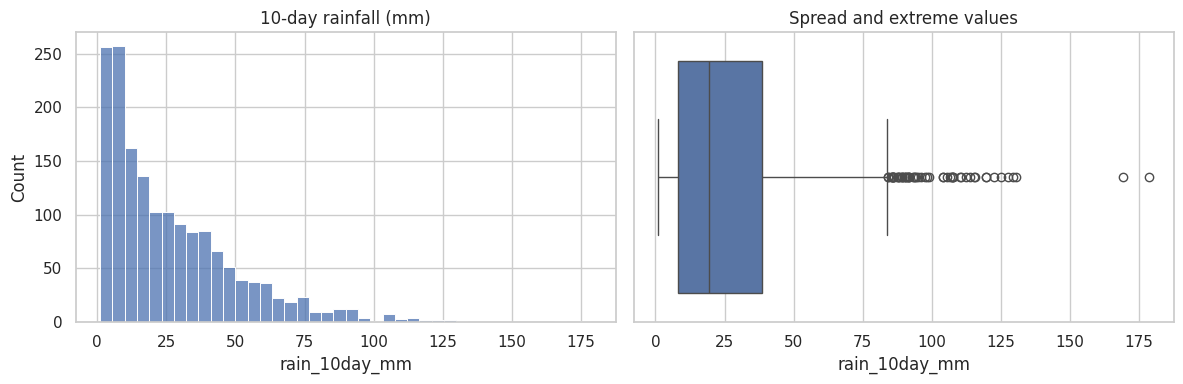

In [6]:
# Summary numbers for 10-day rainfall (mm)
print(df["rain_10day_mm"].describe())

# Share of periods with almost no rain
print("\nPeriods with under 1 mm:", round((df["rain_10day_mm"] < 1).mean() * 100, 1), "%")

# Skewness above 1 means a long tail of very wet periods
print("Skewness:", round(df["rain_10day_mm"].skew(), 2))

# Two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["rain_10day_mm"], bins=40, ax=axes[0])   # how often each amount occurs
axes[0].set_title("10-day rainfall (mm)")
sns.boxplot(x=df["rain_10day_mm"], ax=axes[1])           # median, spread, extreme values
axes[1].set_title("Spread and extreme values")
plt.tight_layout()
plt.show()

### 3.2 Rainfall by month

       mean    p90
month             
1       4.8    9.5
2      11.5   21.7
3      28.2   46.5
4      34.6   59.4
5      51.3   85.4
6      55.6  100.5
7      26.0   58.8
8      14.0   30.5
9      28.5   58.9
10     37.3   61.7
11     19.0   36.9
12      8.8   17.9


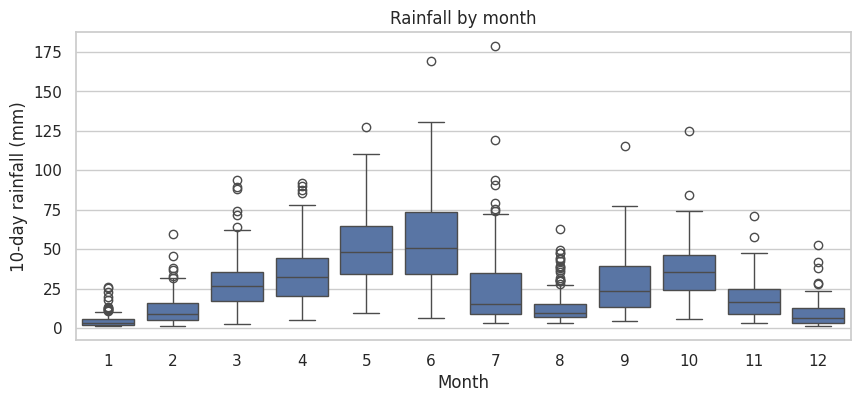

In [7]:
# Add a month column
df["month"] = df["date"].dt.month

# Average and 90th-percentile rainfall for each month
monthly = df.groupby("month")["rain_10day_mm"].agg(
    mean="mean", p90=lambda x: x.quantile(0.90)
).round(1)
print(monthly)

# Box plot of rainfall for each month
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="month", y="rain_10day_mm")
plt.title("Rainfall by month")
plt.xlabel("Month")
plt.ylabel("10-day rainfall (mm)")
plt.show()

### 3.3 Yearly trend

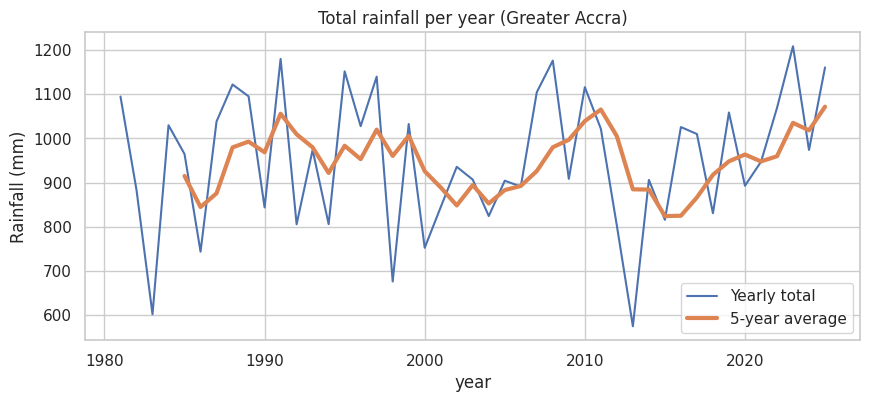

Wettest years:
 year
2023    1209.000000
1991    1180.252176
2008    1176.504358
Name: rain_10day_mm, dtype: float64

Driest years:
 year
2013    574.530438
1983    601.652171
1998    675.956529
Name: rain_10day_mm, dtype: float64


In [8]:
# Add a year column
df["year"] = df["date"].dt.year

# Total rainfall per year (skip 2026, it is not a full year)
yearly = df[df["year"] < 2026].groupby("year")["rain_10day_mm"].sum()

# Line chart of yearly totals with a 5-year average line
plt.figure(figsize=(10, 4))
yearly.plot(label="Yearly total")
yearly.rolling(5).mean().plot(label="5-year average", linewidth=3)
plt.title("Total rainfall per year (Greater Accra)")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.show()

# Show the 3 wettest and 3 driest years
print("Wettest years:\n", yearly.nlargest(3))
print("\nDriest years:\n", yearly.nsmallest(3))

### 3.4 How the rainfall columns relate

                        rain_10day_mm  rain_1month_mm  rain_3month_mm  \
rain_10day_mm                    1.00            0.79            0.43   
rain_1month_mm                   0.79            1.00            0.67   
rain_3month_mm                   0.43            0.67            1.00   
rain_10day_pct_of_avg            0.66            0.36            0.20   
rain_1month_pct_of_avg           0.42            0.53            0.32   
rain_3month_pct_of_avg           0.27            0.36            0.49   

                        rain_10day_pct_of_avg  rain_1month_pct_of_avg  \
rain_10day_mm                            0.66                    0.42   
rain_1month_mm                           0.36                    0.53   
rain_3month_mm                           0.20                    0.32   
rain_10day_pct_of_avg                    1.00                    0.65   
rain_1month_pct_of_avg                   0.65                    1.00   
rain_3month_pct_of_avg                   0.39     

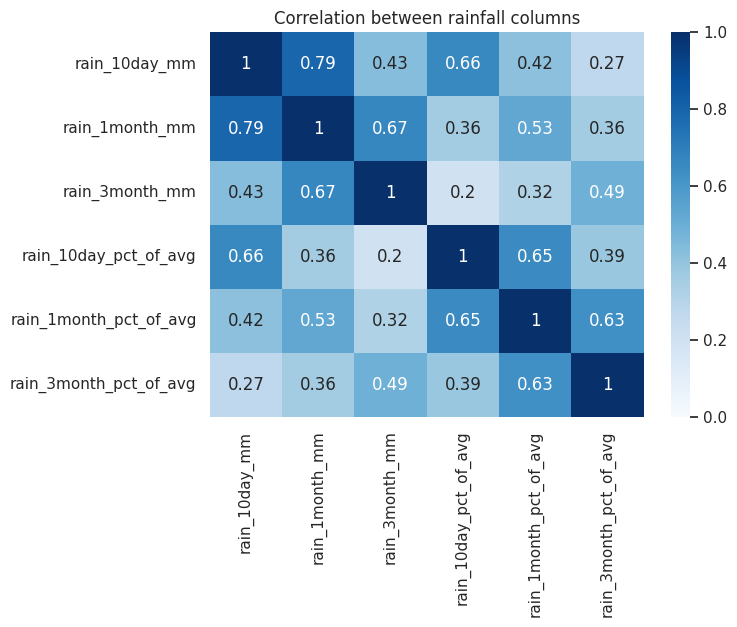

In [9]:
# Choose the rainfall columns to compare
cols = ["rain_10day_mm", "rain_1month_mm", "rain_3month_mm",
        "rain_10day_pct_of_avg", "rain_1month_pct_of_avg", "rain_3month_pct_of_avg"]

# Correlation: 1 means two columns move together, 0 means unrelated
corr = df[cols].corr().round(2)
print(corr)

# Draw the correlations as a colour grid
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=0, vmax=1)
plt.title("Correlation between rainfall columns")
plt.show()

## 4. Defining "heavy rain"
Compare two rules. A cut-off for each month marks about 10% of periods as heavy even
in dry months, which hides the seasons. One fixed cut-off matches the rainy seasons,
so we use it.

In [10]:
# Rule A: heavy = above that month's own 90th percentile (our old rule)
month_cut = df.groupby("month")["rain_10day_mm"].transform(lambda x: x.quantile(0.90))
df["heavy_rule_a"] = (df["rain_10day_mm"] > month_cut).astype(int)

# Rule B: heavy = above the 90th percentile of all periods in the year
overall_cut = df["rain_10day_mm"].quantile(0.90)
df["heavy_rule_b"] = (df["rain_10day_mm"] > overall_cut).astype(int)
print("Rule B cut-off (mm):", round(overall_cut, 1))

# Count heavy periods in each month under each rule
counts = df.groupby("month")[["heavy_rule_a", "heavy_rule_b"]].sum()
print(counts)
print("\nTotals:", counts.sum().to_dict())

Rule B cut-off (mm): 59.7
       heavy_rule_a  heavy_rule_b
month                            
1                14             0
2                14             1
3                14             7
4                14            13
5                14            42
6                14            55
7                14            13
8                14             1
9                14            14
10               14            17
11               14             1
12               14             0

Totals: {'heavy_rule_a': 168, 'heavy_rule_b': 164}


## 5. How predictable is the next period?
Test how much this period tells us about the next one. Once the season is removed the
link is weak (correlation 0.15), and a simple month-by-month lookup is a strong
baseline that any model must beat.

Lag-1 correlation, raw rainfall: 0.5
Lag-1 correlation, season removed: 0.15


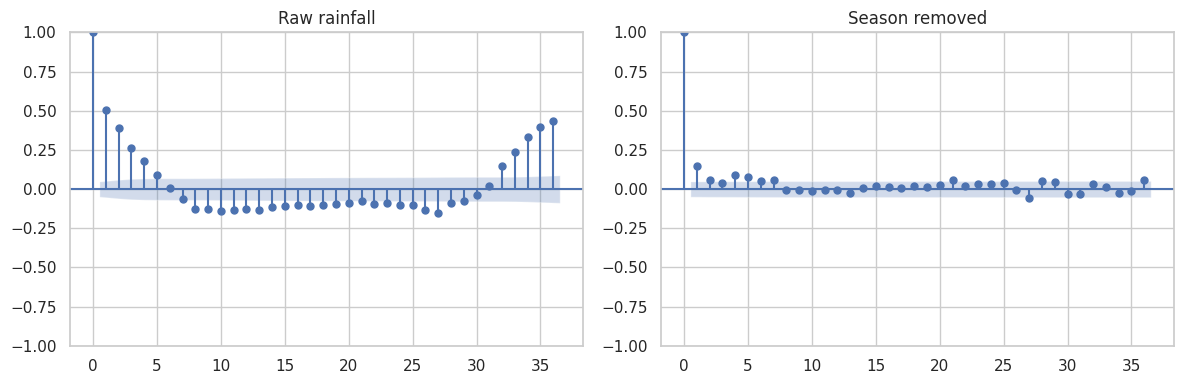

In [11]:
# Remove the season: subtract each month's average rainfall
month_avg = df.groupby("month")["rain_10day_mm"].transform("mean")
df["rain_anomaly_mm"] = df["rain_10day_mm"] - month_avg

# Correlation between one period and the next (1 = perfect link, 0 = no link)
print("Lag-1 correlation, raw rainfall:", round(df["rain_10day_mm"].autocorr(lag=1), 2))
print("Lag-1 correlation, season removed:", round(df["rain_anomaly_mm"].autocorr(lag=1), 2))

# Draw both patterns (36 periods = 1 year)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(df["rain_10day_mm"], lags=36, ax=axes[0])
axes[0].set_title("Raw rainfall")
plot_acf(df["rain_anomaly_mm"], lags=36, ax=axes[1])
axes[1].set_title("Season removed")
plt.tight_layout()
plt.show()

### 5.1 The baselines every model must beat

In [12]:
# Split by time: the first 80% of dates train, the last 20% test
split_date = df["date"].iloc[int(len(df) * 0.8)]
train_part = df[df["date"] < split_date]

# Cut-offs learned from the training part only
cut_b = train_part["rain_10day_mm"].quantile(0.90)                    # one cut-off for all months
cut_a = train_part.groupby("month")["rain_10day_mm"].quantile(0.90)   # one cut-off per month

# Mark each period heavy (1) or not (0) under both rules
df["heavy_a"] = (df["rain_10day_mm"] > df["month"].map(cut_a)).astype(int)
df["heavy_b"] = (df["rain_10day_mm"] > cut_b).astype(int)

# The target is the NEXT period, so shift each answer up one row
df["next_heavy_a"] = df["heavy_a"].shift(-1)
df["next_heavy_b"] = df["heavy_b"].shift(-1)
df["next_month"] = df["month"].shift(-1)

# Drop the last row (it has no next period), then split
data = df.dropna(subset=["next_heavy_a", "next_heavy_b"]).copy()
train = data[data["date"] < split_date]
test = data[data["date"] >= split_date]
print("Train:", len(train), "rows | Test:", len(test), "rows")

# Score two simple baselines under each rule
results = []
for rule in ["a", "b"]:
    target = f"next_heavy_{rule}"
    month_rate = train.groupby("next_month")[target].mean()   # how often each month is heavy
    scores = {
        "Calendar only": test["next_month"].map(month_rate),
        "This period's rain only": test["rain_10day_mm"],
    }
    for name, score in scores.items():
        results.append({
            "Rule": rule.upper(),
            "Baseline": name,
            "AUC": round(roc_auc_score(test[target], score), 3),
            "PR-AUC": round(average_precision_score(test[target], score), 3),
            "Test heavy rate": round(test[target].mean(), 3),
        })

pd.DataFrame(results)

Train: 1310 rows | Test: 327 rows


,Rule,Baseline,AUC,PR-AUC,Test heavy rate
0,A,Calendar only,0.459,0.141,0.150
1,A,This period's rain only,0.626,0.198,0.150
2,B,Calendar only,0.860,0.405,0.128
3,B,This period's rain only,0.783,0.341,0.128


## 6. First model comparison (one split)
Build the model inputs and compare four models on one time-ordered split. Result: all
are close to the month baseline, and one split is too small to decide.
### 6.1 Build the features and the split


In [13]:
# Use the month of the NEXT period, as a point on a circle (so Dec and Jan are close)
df["next_month_sin"] = np.sin(2 * np.pi * df["next_month"] / 12)
df["next_month_cos"] = np.cos(2 * np.pi * df["next_month"] / 12)

# Add the rainfall from 1 and 2 periods ago
df["rain_lag1_mm"] = df["rain_10day_mm"].shift(1)
df["rain_lag2_mm"] = df["rain_10day_mm"].shift(2)

# List the input columns and the answer column (is the next period heavy?)
features = ["rain_10day_mm", "rain_1month_mm", "rain_3month_mm",
            "rain_10day_pct_of_avg", "rain_1month_pct_of_avg", "rain_3month_pct_of_avg",
            "rain_lag1_mm", "rain_lag2_mm", "next_month_sin", "next_month_cos"]
target = "next_heavy_b"

# Keep only rows with no missing values
model_data = df.dropna(subset=features + [target]).copy()

# Split by time using the same split date as before
train = model_data[model_data["date"] < split_date]
test = model_data[model_data["date"] >= split_date]
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print("Train:", len(train), "| Test:", len(test))
print("Heavy rate - train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: 1302 | Test: 327
Heavy rate - train: 0.101 | test: 0.128


### 6.2 Compare the models against the calendar baseline

In [14]:
# Mark test rows whose NEXT period falls in a rainy-season month
rainy_months = [3, 4, 5, 6, 7, 9, 10]
in_season = test["next_month"].isin(rainy_months)

# Small helper: returns AUC and PR-AUC
def score(y_true, prob):
    return round(roc_auc_score(y_true, prob), 3), round(average_precision_score(y_true, prob), 3)

# The models to compare, simple first
models = {
    "Logistic regression": Pipeline([("scale", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                            class_weight="balanced", random_state=RANDOM_SEED),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             subsample=0.8, eval_metric="logloss", random_state=RANDOM_SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                           random_state=RANDOM_SEED),
}

# Baseline: how often each month was heavy in the training years
month_rate = train.groupby("next_month")[target].mean()
cal_score = test["next_month"].map(month_rate)
rows = [["Calendar only", *score(y_test, cal_score), *score(y_test[in_season], cal_score[in_season])]]

# Train each model and score it on all test rows and on rainy-season rows only
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    rows.append([name, *score(y_test, p), *score(y_test[in_season], p[in_season.values])])

# Show the results in one table
result = pd.DataFrame(rows, columns=["Model", "AUC (all)", "PR-AUC (all)",
                                     "AUC (rainy season)", "PR-AUC (rainy season)"])
print("Heavy rate in test - all:", round(y_test.mean(), 3),
      "| rainy season:", round(y_test[in_season].mean(), 3))
result

Heavy rate in test - all: 0.128 | rainy season: 0.219


,Model,AUC (all),PR-AUC (all),AUC (rainy season),PR-AUC (rainy season)
0,Calendar only,0.860,0.405,0.733,0.405
1,Logistic regression,0.852,0.435,0.729,0.437
2,Random Forest,0.849,0.408,0.729,0.411
3,XGBoost,0.827,0.328,0.682,0.329
4,HistGradientBoosting,0.843,0.388,0.718,0.390


## 7. A fairer comparison over five time windows
Repeat the test on five windows, each trained on the past and tested on the future.
SMOTE is used only inside the training part. Result: Random Forest beats the month
baseline in all 5 windows, and SMOTE helps in 4 of 5.
### 7.1 Time-ordered comparison, including SMOTE


In [15]:
# Sort the rows by date (the splits must go forward in time)
cv_data = model_data.sort_values("date").reset_index(drop=True)
X_all = cv_data[features]
y_all = cv_data[target]

# Make 5 splits where training always comes BEFORE testing
tscv = TimeSeriesSplit(n_splits=5)

# The models to compare (SMOTE is used only inside the training part)
candidates = {
    "Logistic regression": Pipeline([("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Logistic + SMOTE": ImbPipeline([("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_SEED)),
        ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
        class_weight="balanced", random_state=RANDOM_SEED),
    "Random Forest + SMOTE": ImbPipeline([("smote", SMOTE(random_state=RANDOM_SEED)),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
        random_state=RANDOM_SEED))]),
}

# A place to store the scores for each model, plus the calendar baseline
scores = {name: {"pr": [], "auc": []} for name in list(candidates) + ["Calendar only"]}

# Go through each time window
for train_idx, test_idx in tscv.split(X_all):
    X_tr, X_te = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_tr, y_te = y_all.iloc[train_idx], y_all.iloc[test_idx]

    # Skip a window that has no heavy periods to test on
    if y_te.sum() == 0:
        continue

    # Baseline: how often each month was heavy in this window's training part
    rate = cv_data.iloc[train_idx].groupby("next_month")[target].mean()
    p_cal = cv_data.iloc[test_idx]["next_month"].map(rate).fillna(y_tr.mean())
    scores["Calendar only"]["pr"].append(average_precision_score(y_te, p_cal))
    scores["Calendar only"]["auc"].append(roc_auc_score(y_te, p_cal))

    # Train each model and score it on this window
    for name, m in candidates.items():
        m.fit(X_tr, y_tr)
        p = m.predict_proba(X_te)[:, 1]
        scores[name]["pr"].append(average_precision_score(y_te, p))
        scores[name]["auc"].append(roc_auc_score(y_te, p))

# Show the average score and the spread across windows
summary = pd.DataFrame({
    name: {"PR-AUC mean": np.mean(v["pr"]), "PR-AUC spread": np.std(v["pr"]),
           "AUC mean": np.mean(v["auc"]), "AUC spread": np.std(v["auc"]),
           "windows used": len(v["pr"])}
    for name, v in scores.items()
}).T.round(3)
summary

,PR-AUC mean,PR-AUC spread,AUC mean,AUC spread,windows used
Logistic regression,0.341,0.096,0.814,0.036,5.0
Logistic + SMOTE,0.348,0.092,0.816,0.035,5.0
Random Forest,0.375,0.068,0.814,0.036,5.0
Random Forest + SMOTE,0.392,0.073,0.816,0.039,5.0
Calendar only,0.331,0.072,0.818,0.039,5.0


### 7.2 Window-by-window check

In [16]:
# Collect each model's PR-AUC for every window so we can compare them directly
rows = []
for i, (train_idx, test_idx) in enumerate(tscv.split(X_all), start=1):
    X_tr, X_te = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_tr, y_te = y_all.iloc[train_idx], y_all.iloc[test_idx]

    # Calendar baseline for this window (built from its training part only)
    rate = cv_data.iloc[train_idx].groupby("next_month")[target].mean()
    p_cal = cv_data.iloc[test_idx]["next_month"].map(rate).fillna(y_tr.mean())

    # Start the row with the window size and the number of heavy periods in it
    row = {
        "window": i,
        "train rows": len(train_idx),
        "test rows": len(test_idx),
        "heavy in test": int(y_te.sum()),
        "Calendar": round(average_precision_score(y_te, p_cal), 3),
    }

    # Train and score the two Random Forest versions
    for name in ["Random Forest", "Random Forest + SMOTE"]:
        m = candidates[name]
        m.fit(X_tr, y_tr)
        row[name] = round(average_precision_score(y_te, m.predict_proba(X_te)[:, 1]), 3)
    rows.append(row)

# Show one row per window
per_window = pd.DataFrame(rows)
print(per_window)

# Count the windows where each model beats the calendar
for name in ["Random Forest", "Random Forest + SMOTE"]:
    wins = (per_window[name] > per_window["Calendar"]).sum()
    print(f"{name} beats calendar in {wins} of {len(per_window)} windows")

# Count the windows where SMOTE beats plain Random Forest
smote_wins = (per_window["Random Forest + SMOTE"] > per_window["Random Forest"]).sum()
print(f"SMOTE beats plain Random Forest in {smote_wins} of {len(per_window)} windows")

   window  train rows  test rows  heavy in test  Calendar  Random Forest  \
0       1         274        271             28     0.316          0.345   
1       2         545        271             30     0.398          0.440   
2       3         816        271             31     0.306          0.359   
3       4        1087        271             24     0.217          0.270   
4       5        1358        271             36     0.417          0.459   

   Random Forest + SMOTE  
0                  0.366  
1                  0.469  
2                  0.356  
3                  0.288  
4                  0.483  
Random Forest beats calendar in 5 of 5 windows
Random Forest + SMOTE beats calendar in 5 of 5 windows
SMOTE beats plain Random Forest in 4 of 5 windows


## 8. Honest scores and risk bands
Use only scores from models that never saw the test period, and group the periods by
score. The real heavy-rain rate rises from about 1% to 35%. SMOTE inflates the raw
scores, so the dashboard shows the real past rate instead.
### 8.1 Observed heavy-rain rate by score group


In [17]:
# Tool for making a fresh copy of a model
from sklearn.base import clone

# Collect honest scores: each window is predicted by a model that saw only the past
oof_rows = []
for train_idx, test_idx in tscv.split(X_all):
    X_tr, y_tr = X_all.iloc[train_idx], y_all.iloc[train_idx]
    X_te = X_all.iloc[test_idx]

    # Train a fresh Random Forest + SMOTE on the past only
    m = clone(candidates["Random Forest + SMOTE"])
    m.fit(X_tr, y_tr)

    # Save each test row's date, true answer and model score
    part = cv_data.iloc[test_idx][["date", target]].copy()
    part["score"] = m.predict_proba(X_te)[:, 1]
    oof_rows.append(part)

# Put all windows together
oof = pd.concat(oof_rows).reset_index(drop=True)

# Sort the rows into 5 equal groups, from lowest score to highest
oof["score_group"] = pd.qcut(oof["score"], q=5,
                             labels=["1 (lowest)", "2", "3", "4", "5 (highest)"])

# For each group: row count, average score, and how often the next period was really heavy
table = oof.groupby("score_group", observed=True).agg(
    rows=("score", "size"),
    avg_score=("score", "mean"),
    real_heavy_rate=(target, "mean"),
).round(3)

# Show the overall heavy rate, then the table
print("Overall heavy rate:", round(oof[target].mean(), 3))
table

Overall heavy rate: 0.11


,rows,avg_score,real_heavy_rate
score_group,,,
1 (lowest),271,0.006,0.007
2,271,0.053,0.026
3,271,0.150,0.066
4,271,0.355,0.103
5 (highest),271,0.696,0.347


### 8.2 Score cut-offs, month mix and skill inside each month


In [18]:
# Add the month of the NEXT period (the one we are predicting) to each row
oof = oof.merge(cv_data[["date", "next_month"]], on="date", how="left")

# Show the lowest and highest score in each group (these become the band cut-offs)
print(oof.groupby("score_group", observed=True)["score"].agg(["min", "max"]).round(3))

# Show how many rows from each month sit in each group
print("\nNext-period month by score group:")
print(pd.crosstab(oof["score_group"], oof["next_month"]))

# Check skill INSIDE each month, where a calendar-only model would score 0.5
rows = []
for m in range(1, 13):
    sub = oof[oof["next_month"] == m]
    # Only test months with at least 10 heavy periods (too few gives unreliable results)
    if sub[target].nunique() == 2 and sub[target].sum() >= 10:
        rows.append({
            "month": m,
            "rows": len(sub),
            "heavy": int(sub[target].sum()),
            "AUC inside month": round(roc_auc_score(sub[target], sub["score"]), 3),
        })
print("\nSkill inside single months (0.5 = no skill beyond the season):")
pd.DataFrame(rows)

               min    max
score_group              
1 (lowest)   0.000  0.020
2            0.021  0.090
3            0.090  0.240
4            0.242  0.489
5 (highest)  0.490  0.923

Next-period month by score group:
next_month   1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0   9.0   10.0  11.0  \
score_group                                                                     
1 (lowest)    100    83    17     1     0     0     0    12    12     0     4   
2              10    25    40     5     0     0     5    62    36    11    36   
3               2     6    40    35     2     1    28    27    32    20    55   
4               2     0    16    58    18     3    55     9    22    62    18   
5 (highest)     0     0     1    15    94   110    23     1     9    18     0   

next_month   12.0  
score_group        
1 (lowest)     42  
2              41  
3              23  
4               8  
5 (highest)     0  

Skill inside single months (0.5 = no skill beyond the season):


,month,rows,heavy,AUC inside month
0,4,114,16,0.441
1,5,114,38,0.604
2,6,114,49,0.578
3,7,111,11,0.591
4,9,111,10,0.735
5,10,111,15,0.465


## 9. Reality check against documented floods
Compare the model's scores with four documented Accra floods (June 2015, March 2023,
October 2023 and June 2026). Two were rated High and were followed by heavy rain, and
two were not flagged.

In [19]:
# Put the honest scores next to the rainfall for each period
check = oof.merge(cv_data[["date", "rain_10day_mm"]], on="date", how="left")

# Turn each score into a band using the cut-offs above
check["band"] = pd.cut(check["score"], bins=[0, 0.24, 0.49, 1.0],
                       labels=["Low", "Typical", "High"], include_lowest=True)

# Show the periods around the two documented floods
for label, start, end in [("June 2015 flash flood", "2015-05-01", "2015-07-10"),
                          ("October 2023 flood", "2023-09-11", "2023-11-10")]:
    window = check[(check["date"] >= start) & (check["date"] <= end)]
    print(label)
    print(window[["date", "rain_10day_mm", "score", "band", target]].round(2).to_string(index=False))
    print()

June 2015 flash flood
      date  rain_10day_mm  score band  next_heavy_b
2015-05-01          26.94   0.85 High           0.0
2015-05-11          31.65   0.86 High           0.0
2015-05-21          40.42   0.87 High           1.0
2015-06-01          99.01   0.90 High           0.0
2015-06-11          50.12   0.85 High           0.0
2015-06-21           8.38   0.16  Low           0.0
2015-07-01          41.55   0.17  Low           0.0

October 2023 flood
      date  rain_10day_mm  score    band  next_heavy_b
2023-09-11          43.58   0.55    High           0.0
2023-09-21          55.39   0.46 Typical           0.0
2023-10-01          33.37   0.48 Typical           0.0
2023-10-11          49.83   0.46 Typical           0.0
2023-10-21          41.84   0.17     Low           0.0
2023-11-01          34.63   0.15     Low           0.0



More documented floods: March 2023 and June 2026.


In [20]:
# Two more documented floods to compare with the model's scores
for label, start, end in [("March 2023 Accra flood", "2023-02-01", "2023-03-31"),
                          ("June 2026 Accra flood", "2026-05-11", "2026-06-21")]:
    # Pick the rows around each flood
    window = check[(check["date"] >= start) & (check["date"] <= end)]
    print(label)
    print(window[["date", "rain_10day_mm", "score", "band", target]].round(2).to_string(index=False))
    print()

March 2023 Accra flood
      date  rain_10day_mm  score    band  next_heavy_b
2023-02-01           5.83   0.00     Low           0.0
2023-02-11           8.18   0.01     Low           0.0
2023-02-21          15.10   0.05     Low           0.0
2023-03-01          54.78   0.39 Typical           0.0
2023-03-11          26.72   0.44 Typical           0.0
2023-03-21          46.96   0.35 Typical           0.0

June 2026 Accra flood
      date  rain_10day_mm  score band  next_heavy_b
2026-05-11          76.16   0.65 High           1.0
2026-05-21          85.20   0.82 High           1.0
2026-06-01         115.58   0.62 High           1.0
2026-06-11          58.81   0.59 High           1.0



10. Does recent rain add anything beyond the season?
Compare the full model with a model that knows only the month. The full model wins in
all 5 windows, with a small average gain of 0.06.

In [21]:
# The season-only model sees just the month features
season_features = ["next_month_sin", "next_month_cos"]

rows = []
for i, (train_idx, test_idx) in enumerate(tscv.split(X_all), start=1):
    X_tr, X_te = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_tr, y_te = y_all.iloc[train_idx], y_all.iloc[test_idx]

    # Full model: uses all the features
    full = clone(candidates["Random Forest + SMOTE"]).fit(X_tr, y_tr)
    p_full = full.predict_proba(X_te)[:, 1]

    # Season-only model: same type, month features only
    season = clone(candidates["Random Forest + SMOTE"]).fit(X_tr[season_features], y_tr)
    p_season = season.predict_proba(X_te[season_features])[:, 1]

    # Score both on this window
    rows.append({
        "window": i,
        "Season only": round(average_precision_score(y_te, p_season), 3),
        "Full model": round(average_precision_score(y_te, p_full), 3),
    })

# Show one row per window, then summarise
compare = pd.DataFrame(rows)
print(compare)
print("Full model beats season-only in", (compare["Full model"] > compare["Season only"]).sum(),
      "of", len(compare), "windows")
print("Average gain:", round((compare["Full model"] - compare["Season only"]).mean(), 3))

   window  Season only  Full model
0       1        0.317       0.366
1       2        0.402       0.469
2       3        0.310       0.356
3       4        0.215       0.288
4       5        0.418       0.483
Full model beats season-only in 5 of 5 windows
Average gain: 0.06


11. Which inputs matter most?
Shuffle each input in turn and measure how much the model's PR-AUC drops. A bigger
drop means the model relies on that input more.


                        avg_drop_in_PR_AUC  windows_where_it_helped
rain_lag1_mm                         0.064                        5
next_month_cos                       0.059                        5
next_month_sin                       0.056                        5
rain_10day_mm                        0.028                        4
rain_3month_pct_of_avg               0.015                        3
rain_1month_mm                       0.010                        5
rain_lag2_mm                         0.006                        3
rain_1month_pct_of_avg               0.004                        3
rain_10day_pct_of_avg               -0.003                        2
rain_3month_mm                      -0.004                        2


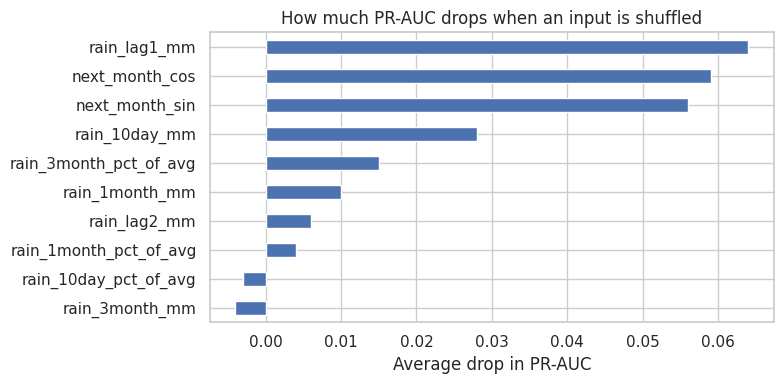

In [22]:
# Tools for importance scores and for copying a model
from sklearn.inspection import permutation_importance
from sklearn.base import clone

rows = []
for train_idx, test_idx in tscv.split(X_all):
    # Split this window into past (train) and future (test)
    X_tr, y_tr = X_all.iloc[train_idx], y_all.iloc[train_idx]
    X_te, y_te = X_all.iloc[test_idx], y_all.iloc[test_idx]

    # Skip a window that has no heavy periods to test on
    if y_te.sum() == 0:
        continue

    # Train a fresh Random Forest + SMOTE on the past only
    m = clone(candidates["Random Forest + SMOTE"]).fit(X_tr, y_tr)

    # Shuffle one input at a time and see how much the PR-AUC score drops
    r = permutation_importance(m, X_te, y_te, scoring="average_precision",
                               n_repeats=20, random_state=RANDOM_SEED)
    rows.append(pd.Series(r.importances_mean, index=features))

# One row per window, one column per input
imp = pd.DataFrame(rows)

# Average drop, and how many windows the input helped (drop above zero)
summary_imp = pd.DataFrame({
    "avg_drop_in_PR_AUC": imp.mean(),
    "windows_where_it_helped": (imp > 0).sum(),
}).sort_values("avg_drop_in_PR_AUC", ascending=False).round(3)
print(summary_imp)

# Bar chart of the average drop for each input
plt.figure(figsize=(8, 4))
summary_imp["avg_drop_in_PR_AUC"].sort_values().plot(kind="barh")
plt.title("How much PR-AUC drops when an input is shuffled")
plt.xlabel("Average drop in PR-AUC")
plt.tight_layout()
plt.show()

12. Final model and saved files
Train the final model (Random Forest + SMOTE, 10 inputs) on all rows and save the
files the dashboard needs.
### 12.1 The real cut-off and the band statistics

In [23]:
# Show the cut-off (in mm) that defines "heavy rain" in our target
print("Heavy-rain cut-off used for the target (mm):", round(cut_b, 1))

# Turn the honest scores into the 3 dashboard bands
oof["band"] = pd.cut(oof["score"], bins=[0, 0.24, 0.49, 1.0],
                     labels=["Low", "Typical", "High"], include_lowest=True)

# For each band: how many periods, how many were really heavy, and the real heavy rate
band_table = oof.groupby("band", observed=True).agg(
    periods=("score", "size"),
    heavy=(target, "sum"),
    real_heavy_rate=(target, "mean"),
).round(3)

# Add each band's share of all periods
band_table["share_of_periods"] = (band_table["periods"] / len(oof)).round(3)
band_table

Heavy-rain cut-off used for the target (mm): 58.4


,periods,heavy,real_heavy_rate,share_of_periods
band,,,,
Low,812,27.0,0.033,0.599
Typical,272,28.0,0.103,0.201
High,271,94.0,0.347,0.200


12.2 Train the final model and save everything the dashboard needs

In [24]:
import json
import sklearn
import imblearn

# Train the final model on all available rows
final_model = clone(candidates["Random Forest + SMOTE"])
final_model.fit(X_all, y_all)

# Make sure the output folders exist
MODEL_DIR = BASE_DIR / "models"
PROC_DIR = BASE_DIR / "data" / "processed"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

# Save the model
joblib.dump(final_model, MODEL_DIR / "flood_model_v2.pkl")

# Save the settings the dashboard needs
settings = {
    "features": features,
    "heavy_rain_cutoff_mm": float(cut_b),
    "band_cutoffs": {"low_max": 0.24, "high_min": 0.49},
    "band_real_heavy_rate": {str(k): float(v) for k, v in band_table["real_heavy_rate"].items()},
    "note": "Bands use real past heavy-rain rates. Raw scores are inflated by SMOTE.",
}
with open(MODEL_DIR / "settings.json", "w") as f:
    json.dump(settings, f, indent=2)

# Save the feature table so the dashboard can look up any date
cv_data[["date", "next_month"] + features + [target]].to_csv(
    PROC_DIR / "model_features_v2.csv", index=False)

# Print the library versions (copy these into requirements.txt)
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("Saved model, settings and features.")

scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
pandas: 2.2.3 | numpy: 2.4.6
Saved model, settings and features.


## 13. Summary and limitations

**Data:** HDX rainfall for Greater Accra (region level), 1,638 ten-day periods from
1981 to 2026. No gaps or repeated dates. The only missing values are the first rows
of each rolling total, because those totals need earlier data.

**Target:** No flood records were available, so the target is a stand-in: the next
10-day period is "heavy" if rainfall exceeds 58.4 mm (the 90th percentile of the
training years). It measures heavy rainfall. It does not detect floods.

**Predictability:** Once the season is removed, this period explains little of the
next one (correlation 0.15, against 0.50 before removing the season).

**Model comparison (5 time windows):** Average PR-AUC was 0.331 for the month-only
baseline, 0.375 for Random Forest and 0.392 for Random Forest + SMOTE. Both models
beat the baseline in all 5 windows, and SMOTE beat plain Random Forest in 4 of 5.
On plain AUC, no model beat the baseline (all were between 0.814 and 0.818).

**Season check:** The full model beat a month-only model in all 5 windows (average
gain 0.06 PR-AUC). The gain is small, and only five windows were tested. Inside
single months the model's ranking was only slightly better than chance in May and
June (AUC about 0.58 to 0.60), and not better in April or October. Each month had
only 10 to 49 heavy periods, so these figures are rough.

**Input importance (RQ2):** Each input was shuffled in turn and the drop in PR-AUC
was measured across 5 windows. The model relied most on the previous period's
rainfall, the month (two inputs, sine and cosine) and the current period's rainfall.
The three-month total and the 10-day "percent of average" did not help. Rankings
among the overlapping rainfall inputs are unstable, and importance shows what the
model uses, not what causes heavy rain.

**Final model:** Random Forest + SMOTE with 10 inputs. Risk bands use real past
rates because SMOTE inflates the raw scores: Low (score up to 0.24, about 3% of
periods were followed by heavy rain), Typical (0.24 to 0.49, about 10%) and High
(above 0.49, about 35%). High holds 94 of the 149 heavy periods in 20% of periods.

**Reality check:** Four documented floods were compared with the model's score for
the period each fell in. Two (June 2015 and June 2026) were rated High and were
followed by heavy rain. Two were not flagged: in March 2023 regional rainfall was
54.8 mm, just under the 58.4 mm cut-off, and the model rated it Low; October 2023
had no heavy period and was rated Typical. Both hits were in the peak season,
when High covers most periods, so these events show the model behaves sensibly,
not that it beats a month lookup. Four events is too few to give a hit rate.

**Limitations:** The target is a stand-in for flooding, the data is a region-wide
average that smooths local downpours, and heavy periods are few (about 10% of all
periods). The risk bands mostly follow the season, and High stays on for weeks in
the rainy season. The final model is trained on all rows, so its scores may differ
slightly from the cut-offs measured on earlier windows.